# Financial Health of Vietnamese Steel Producers, 2021–2025

<p class="byline">Hoang Duc Binh<br><span>November 2026</span></p>

<div class="abstract">
<p><strong>Abstract.</strong> This report assesses the financial health of four listed Vietnamese steel producers, Hoa Phat (HPG), Hoa Sen (HSG), Nam Kim (NKG) and Ton Dong A (GDA), through the 2021 steel boom and the 2022–2023 downturn, using audited consolidated financial statements for 2020–2025. It combines ratio analysis with the Altman Z-score, in both its original and emerging-market versions, and the Piotroski F-score. All four firms earned a return on equity of 35–40% in 2021; returns then collapsed, and in 2022 two of the four could not cover their interest expense from operating profit. None entered the distress zone of either Altman model. By 2025, Hoa Sen has the strongest balance sheet, Hoa Phat the highest profitability, and Ton Dong A the weakest financial position. The original Z-score penalises capital-intensive integrated producers, which supports using the emerging-market version for Vietnamese firms.</p>
<p><strong>Keywords:</strong> financial distress, Altman Z-score, Piotroski F-score, ratio analysis, Vietnam, steel industry</p>
</div>

## Research question

How did four listed Vietnamese steel producers — the country's largest integrated steelmaker, Hoa Phat (HPG), and three leading coated-steel makers, Hoa Sen (HSG), Nam Kim (NKG) and Ton Dong A (GDA) — come through the 2021 steel boom and the 2022–2023 downturn, and which of them is financially strongest going into 2026?

## Method

1. Profitability, liquidity, solvency and efficiency ratios
2. **Altman Z-score**: the original US version and the emerging-market Z''-score, to test whether a model built on US firms fits Vietnamese ones
3. **Piotroski F-score**: nine signals of improving or weakening fundamentals
4. A scorecard for the latest year and a conclusion

## 1. Data

The data are the audited consolidated financial statements of the four companies for 2020–2025. All amounts are in billion VND, except the number of shares (millions) and the share price (VND). 2020 is used only as the base year for growth rates and the Piotroski F-score. The full input data are in Appendix A, and the sources are listed under Sources.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import steel_analysis as sa

sa.use_report_style()
data = sa.load_financials("data/steel_financials.csv")
LATEST = data.index.get_level_values("year").max()

overview = data.xs(LATEST, level="year")[["revenue", "net_income", "total_assets", "total_equity"]].copy()
overview.insert(0, "name", overview.index.map(sa.COMPANY_NAMES))
sa.show(overview, title=f"The four companies in {LATEST} (billion VND)", decimals=0)

Company,Name,Revenue,Net income,Total assets,Total equity
GDA,Ton Dong A,"15,310",272,"11,901","3,967"
HPG,Hoa Phat Group,"156,116","15,515","257,899","131,220"
HSG,Hoa Sen Group,"36,538",735,"18,953","11,339"
NKG,Nam Kim Steel,"14,808",197,"16,494","7,635"


In [2]:
ratios = sa.compute_ratios(data)
altman = sa.altman_z(data)
fscore = sa.piotroski(data)

# The analysis window (the first year in the data is only used as the 'previous year')
YEARS = sorted(data.index.get_level_values("year").unique())[1:]
LATEST = YEARS[-1]

## 2. Profitability: who earns the most on each dong of sales and capital?

Steel margins depend on the *spread* between steel prices and input costs (iron ore, coking coal and scrap). This section measures how far each company's margins fell in 2022–2023 and how quickly they recovered.

Company,2020,2021,2022,2023,2024,2025
GDA,2.3%,4.8%,-1.3%,1.6%,1.8%,1.8%
HPG,15.0%,23.1%,6.0%,5.7%,8.7%,9.9%
HSG,4.2%,8.9%,0.5%,0.1%,1.3%,2.0%
NKG,2.6%,7.9%,-0.5%,0.6%,2.2%,1.3%


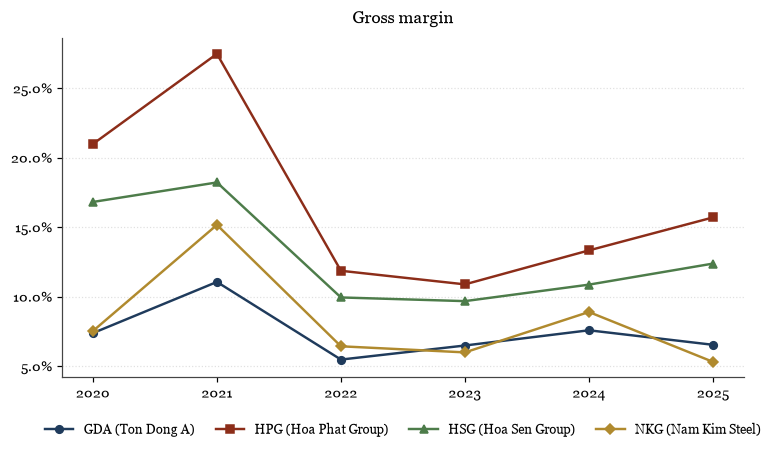

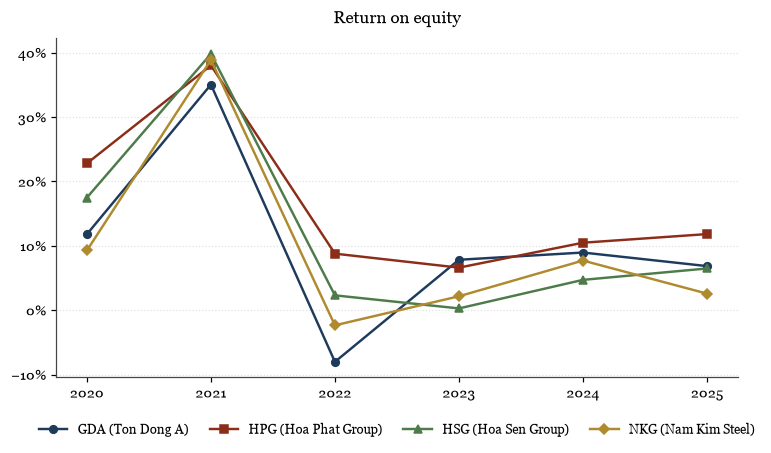

In [3]:
sa.plot_metric(ratios, "Gross margin", "Gross margin", percent=True)
sa.plot_metric(ratios, "ROE", "Return on equity", percent=True)
sa.show(sa.by_year(ratios, "Net margin"), title="Net margin", percent=True)

**Interpretation**

- **Hoa Phat earns far more on each dong of sales.** In 2025 its gross margin was 16% and its net margin 10%, against 5–12% gross and 1–2% net for the other three. The likely reason is the business model. Hoa Phat is integrated: it turns iron ore and coal into steel in its own blast furnaces, so it keeps the margin along the whole chain. Hoa Sen, Nam Kim and Ton Dong A mainly buy hot-rolled coil and galvanise or paint it, so they only earn a processing spread.
- **2021 was exceptional, and the fall was steep.** ROE was 35–40% for all four at the 2021 price peak. In 2022–2023 it collapsed to between –8% and 9%: Nam Kim (ROE –2%) and Ton Dong A (–8%) made losses in 2022, and Hoa Sen's net margin fell to 0.1% in FY2023.
- **The recovery is uneven.** Hoa Phat's ROE has climbed back to 12% in 2025 with revenue up 12%. The three coated-steel makers are still at 3–7% ROE, well below what shareholders would normally require, and their 2025 revenue fell (Nam Kim –28%, Ton Dong A –20%, Hoa Sen –7%).

## 3. Liquidity and solvency: could they survive a bad year?

Vietnamese steel firms rely heavily on short-term bank loans to finance inventory, so liquidity and interest coverage are central to their financial health.

Company,2020,2021,2022,2023,2024,2025
GDA,0.98,1.06,1.10,1.10,1.15,1.18
HPG,1.09,1.28,1.29,1.16,1.15,1.10
HSG,1.00,1.30,1.64,1.72,1.64,1.54
NKG,1.10,1.27,1.28,1.37,1.34,1.48


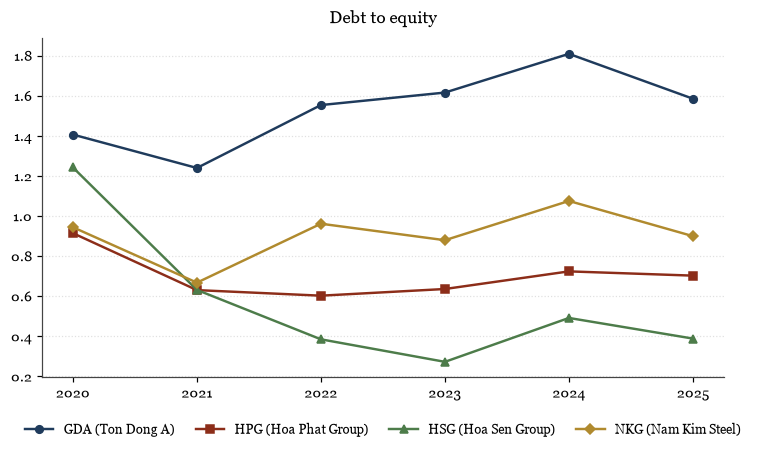

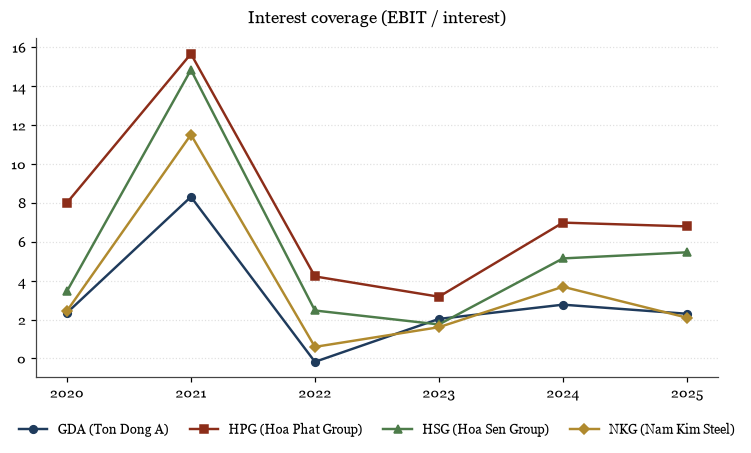

In [4]:
sa.plot_metric(ratios, "Debt to equity", "Debt to equity")
sa.plot_metric(ratios, "Interest coverage", "Interest coverage (EBIT / interest)")
sa.show(sa.by_year(ratios, "Current ratio"), title="Current ratio (current assets / current liabilities)")

**Interpretation**

- **Ton Dong A is the most indebted.** Its debt to equity has been above 1.2 every year and was 1.59 in 2025, with net debt at about 6x EBITDA. Nam Kim comes next (0.90, and 7.3x EBITDA because profit fell while it took on new long-term loans in 2025). Hoa Sen is the least indebted (0.39): it has cut debt to equity from 1.24 in FY2020 and has had no long-term borrowings since FY2023.
- **Two companies fell below 1.5x interest coverage.** In 2022 Nam Kim's operating profit covered its interest only 0.6 times, and Ton Dong A made an operating loss (coverage below zero). This is the clearest sign of financial stress in the data. Both recovered, but in 2025 their cover is still thin (Ton Dong A 2.3x, Nam Kim 2.1x) compared with Hoa Phat (6.8x) and Hoa Sen (5.5x).
- **Liquidity depends on inventory and bank loans.** Current ratios are all above 1, but quick ratios are only 0.46–0.71 in 2025: most short-term assets are steel inventory funded by short-term bank loans. This is normal for the sector, but it makes these firms sensitive to tighter bank credit.

## 4. Efficiency: inventory is the hidden risk in steel

When steel prices fall, a company holding a lot of expensive inventory has to write it down. High inventory days going into 2022 should therefore be a warning sign.

Company,2020,2021,2022,2023,2024,2025
GDA,"1,120",452,"-1,157",208,-607,145
HPG,-328,"15,099","-5,610","-8,731","-28,887","-8,382"
HSG,"1,711","1,019","2,381","1,492","-2,185","1,062"
NKG,-39,-453,"-1,039",138,"-1,444","-2,104"


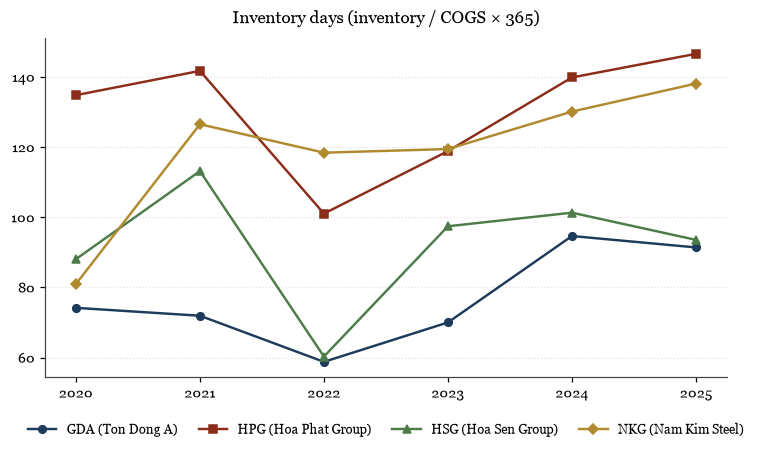

In [5]:
sa.plot_metric(ratios, "Inventory days", "Inventory days (inventory / COGS × 365)")
sa.show(sa.by_year(ratios, "Free cash flow"), title="Free cash flow (billion VND)", decimals=0)

**Interpretation**

- **High inventory predicted the 2022 losses only partly.** Going into 2022, Nam Kim (126 days) and Hoa Sen (113 days) held the most inventory of the coated-steel makers, and Nam Kim made a loss in 2022. But Ton Dong A had the leanest inventory (72 days) and still lost money, while Hoa Phat held the most (142 days) and stayed profitable. High inventory added risk, but the thickness of the margin mattered more.
- **Hoa Sen reacted fastest.** It cut inventory from 113 to 60 days in FY2022. This released cash (free cash flow of +2,381 billion VND) that it used to repay debt.
- **Hoa Phat's negative free cash flow is investment, not weakness.** Its free cash flow has been negative every year since 2022 (–28,887 billion VND in 2024), even though operating cash flow stayed positive. The cause is very heavy capital spending, most of it on the new Dung Quat 2 steel complex. This explains its rising debt. Nam Kim also spent heavily in 2025 (capex of 3,431 billion VND, about a fifth of its total assets).
- **Inventory is building up again.** Since 2022, inventory days have risen for all four companies (Hoa Phat 147, Nam Kim 138 in 2025). That is worth watching if steel prices fall again.

## 5. Altman Z-score: does a US model work in Vietnam?

The original Z-score was estimated on US manufacturers in 1968. Altman later developed the **Z''-score** for emerging markets, which uses the book value of equity and drops the sales term, because asset turnover differs widely across countries and industries. Comparing the two versions tests whether a model built on US firms can be applied to Vietnamese ones.

Company,Year,Altman Z (original),Zone (original),Altman Z'' (emerging markets),Zone (EM)
GDA,2020,–,n/a,4.46,Grey
GDA,2021,–,n/a,5.34,Grey
GDA,2022,–,n/a,4.62,Grey
GDA,2023,2.18,Grey,4.99,Grey
GDA,2024,2.18,Grey,5.18,Grey
GDA,2025,1.97,Grey,5.32,Grey
HPG,2020,2.54,Grey,5.79,Grey
HPG,2021,3.46,Safe,7.36,Safe
HPG,2022,2.33,Grey,6.47,Safe
HPG,2023,2.36,Grey,6.02,Safe


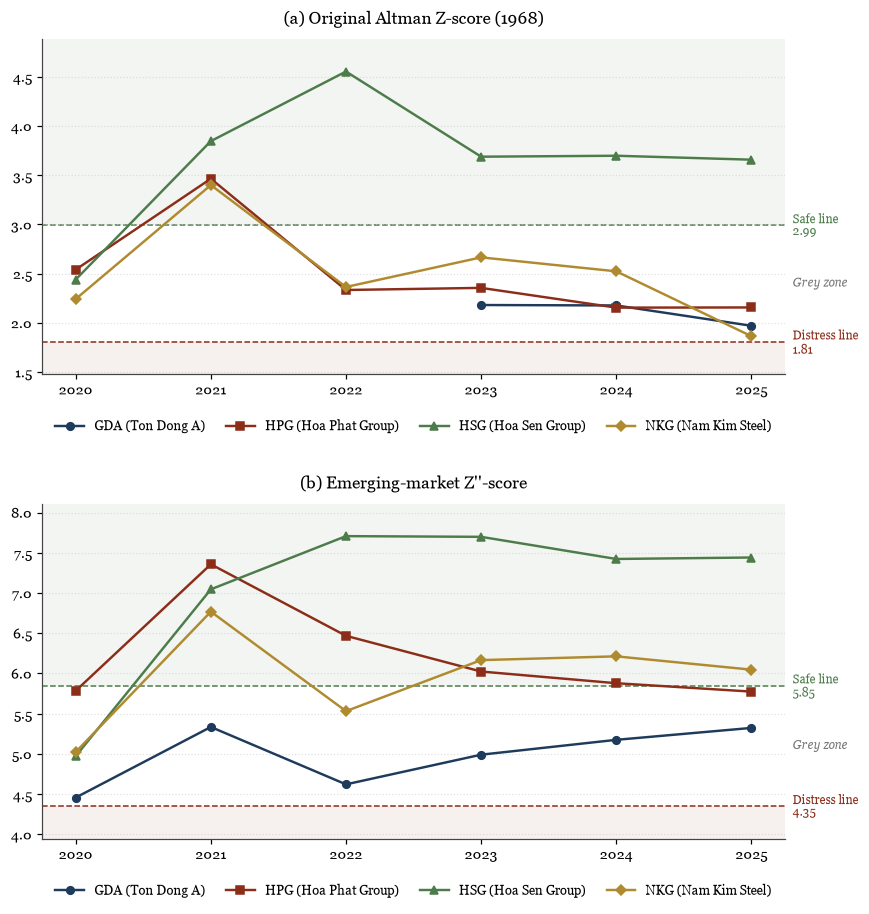

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(8, 8.4))
sa.plot_metric(altman, "Altman Z (original)", "(a) Original Altman Z-score (1968)", zones=sa.ALTMAN_ORIGINAL_ZONES, ax=axes[0])
sa.plot_metric(altman, "Altman Z'' (emerging markets)", "(b) Emerging-market Z''-score", zones=sa.ALTMAN_EM_ZONES, ax=axes[1])
plt.tight_layout(h_pad=2.5)

sa.show(
    altman[["Altman Z (original)", "Zone (original)", "Altman Z'' (emerging markets)", "Zone (EM)"]],
    title="Altman Z-scores and zones",
)

**Interpretation**

- **The two versions do not fully agree, and the sales term (X5) is the main reason.** The original Z-score puts Hoa Sen in the safe zone (3.66) but Hoa Phat (2.16), Ton Dong A (1.97) and Nam Kim (1.86) in the grey zone, with Nam Kim close to the distress line of 1.81. Hoa Phat's asset turnover is only 0.61 because blast furnaces need a lot of capital, and the original model rewards high sales relative to assets. The Z'' version drops that term: it puts Hoa Sen (7.44) and Nam Kim (6.05) in the safe zone and Hoa Phat (5.77) and Ton Dong A (5.32) in the grey zone. Nam Kim scores well on Z'' mainly because of its large working capital (X1 = 0.19, against 0.04 for Hoa Phat), which Z'' weights heavily.
- **The scores matched what happened, but gave little early warning.** No company fell into the distress zone of either model in any year. That fits reality: Nam Kim and Ton Dong A were under real stress in 2022, but neither defaulted and both returned to profit in 2023. However, both models only showed the stress as a drop in score in the same year, not before it.
- **Conclusion on the models:** the Z'' score is the better fit for Vietnamese steel firms, because it does not penalise capital-heavy producers. Its thresholds were not set on Vietnamese data, though, so it is most useful for ranking the firms and following trends, not as an absolute verdict.

## 6. Piotroski F-score: are fundamentals improving?

The F-score adds up nine yes-or-no tests of profitability, funding and efficiency. A score of 8–9 indicates strong and improving fundamentals; 0–2 indicates weak and deteriorating ones.

In [7]:
sa.show(sa.by_year(fscore, "F-Score"), title="Piotroski F-score (0–9)", decimals=0)

Company,2020,2021,2022,2023,2024,2025
GDA,–,7,3,7,5,4
HPG,–,7,5,5,4,6
HSG,–,7,6,5,5,5
NKG,–,6,2,7,4,4


In [8]:
# Which of the nine signals passed in the latest year (1 = yes)
sa.show(fscore.xs(LATEST, level="year").T, title=f"Piotroski signals passed in {LATEST} (1 = yes)", row_label="Signal", decimals=0)

Signal,GDA,HPG,HSG,NKG
1 ROA > 0,1,1,1,1
2 CFO > 0,1,1,1,1
3 ROA improved,0,1,1,0
4 CFO > net income,1,1,1,1
5 Long-term debt ratio fell,0,1,0,0
6 Current ratio improved,1,0,0,1
7 No new shares issued,0,0,0,0
8 Gross margin improved,0,1,1,0
9 Asset turnover improved,0,0,0,0
F-Score,4,6,5,4


**Interpretation**

- **Hoa Phat improved most in 2025.** Its F-score rose from 4 to 6, driven by higher return on assets, a better gross margin and a lower long-term debt ratio. Hoa Sen scores 5. Nam Kim and Ton Dong A score 4: their return on assets and gross margins fell in 2025.
- **The biggest rebound was in 2023.** Nam Kim jumped from 2 to 7 and Ton Dong A from 3 to 7, mainly because they returned to profit and positive operating cash flow. The F-score rewards improvement, so a recovery from a very weak year scores highly.
- **No company scores 8–9 (strong) in 2025.** Asset turnover fell for all four companies in 2025, and every company increased its number of shares, which fails signal 7. Part of this reflects stock dividends (Hoa Phat, for example, paid one in 2025), which raise no cash, so this signal can be harsher on Vietnamese firms than Piotroski intended.

## 7. Scorecard for the latest year

The table below brings the main measures together for the latest financial year.

In [9]:
sa.show(
    sa.snapshot(
        LATEST,
        ratios,
        altman,
        fscore,
        metrics=[
            "Revenue growth",
            "Gross margin",
            "ROE",
            "Debt to equity",
            "Interest coverage",
            "Inventory days",
            "Altman Z'' (emerging markets)",
            "Zone (EM)",
            "F-Score",
            "P/B",
        ],
    ),
    title=f"Scorecard, {LATEST}",
    percent=["Revenue growth", "Gross margin", "ROE"],
)

Metric,GDA,HPG,HSG,NKG
Revenue growth,-20.0%,12.4%,-7.0%,-28.1%
Gross margin,6.5%,15.7%,12.4%,5.3%
ROE,6.9%,11.8%,6.5%,2.6%
Debt to equity,1.59,0.70,0.39,0.90
Interest coverage,2.30,6.79,5.46,2.10
Inventory days,91.37,146.50,93.52,138.03
Altman Z'' (emerging markets),5.32,5.77,7.44,6.05
Zone (EM),Grey,Grey,Safe,Safe
F-Score,4,6,5,4
P/B,0.61,1.54,1.04,0.87


## 8. Conclusion

Hoa Sen and Hoa Phat came out of the downturn strongest, in different ways. **Hoa Sen has the strongest balance sheet**: the lowest debt (debt to equity 0.39, no long-term borrowings), the highest Altman scores in both versions, and it used the downturn to cut inventory and repay debt. Its weakness is thin profitability (ROE 6.5%). **Hoa Phat is the most profitable** (ROE 12%, net margin 10%, F-score 6) thanks to its integrated model, but heavy investment in Dung Quat 2 has made free cash flow strongly negative and pushed up its debt. **Ton Dong A is the most vulnerable**: it has the highest leverage, thin interest cover (2.3 times), the lowest Z'' score and falling revenue. Nam Kim sits in between. Next, I would watch whether Hoa Phat's new capacity lifts its returns enough to justify the investment, and whether the coated-steel makers' falling revenue and rising inventory stabilise.

## 9. Limitations

- Both scoring models were built on US data, so their thresholds may not suit Vietnamese firms.
- Hoa Sen's financial year ends on 30 September, so its years are not perfectly aligned with the other three companies.
- Year-end balances are used instead of averages, and the sample is small (4 companies).
- Ton Dong A had no public share price in 2020–2022, so its original Altman Z-score, P/E and P/B are missing for those years.
- Stock dividends and employee share issues count as "new shares" in the Piotroski F-score, even though no cash was raised.
- The share count is charter capital divided by par value and ignores small holdings of treasury shares.
- The analysis uses only financial statements. It does not model steel prices, input costs or the trade-defence duties that affect exporters of coated steel.

## Sources

All financial figures come from each company's **audited consolidated financial statements**, prepared under Vietnamese Accounting Standards. Each report covers two financial years, and each year uses the most recent report that contains it, so restated figures are used where they exist.

| Company | Reports used (financial years) | Auditor | Published by |
|---|---|---|---|
| Hoa Phat Group (HPG) | 2025, 2023 and 2021 reports | KPMG (2021, 2023 reports) | hoaphat.com.vn |
| Hoa Sen Group (HSG) | FY2025, FY2023 and FY2021 reports (years ending 30 September) | PwC (FY2025), KPMG (FY2021, FY2023) | hoasengroup.vn |
| Nam Kim Steel (NKG) | 2025, 2023 and 2021 reports | PwC (2023, 2025 reports) | Copies of the official filings from the Vietstock document library |
| Ton Dong A (GDA) | 2025, 2023 and 2021 reports | EY (2023 report) | tondonga.com.vn |

**Share prices** are the unadjusted closing price on the last trading day of each financial year, from CafeF (cafef.vn); for Hoa Sen this is the last trading day of September. Ton Dong A had no public trading price in 2020–2022. Its 2023–2025 prices are the average price on the last trading day of the year, from Vietstock (vietstock.vn).

**Number of shares** is the charter capital divided by the par value of 10,000 VND.

## Appendix A. Input data

All figures are in billion VND, except the number of shares (millions) and the year-end share price (VND).

In [10]:
for ticker in data.index.get_level_values("ticker").unique():
    display(sa.show(data.xs(ticker).T, title=f"Input data: {sa.COMPANY_NAMES[ticker]} ({ticker})", row_label="Item", decimals=1))

Item,2020,2021,2022,2023,2024,2025
Revenue,"12,361.0","25,261.7","21,614.5","17,434.6","19,135.8","15,310.4"
Cost of goods sold,"11,450.0","22,470.0","20,433.4","16,305.4","17,686.8","14,310.9"
Profit before tax,347.6,"1,503.5",-292.6,305.9,428.1,355.9
Interest expense,258.6,205.6,248.6,296.6,242.6,274.5
Net income,286.1,"1,209.8",-276.5,283.6,341.8,271.9
Depreciation,336.4,342.2,344.5,345.1,349.2,264.7
Cash,378.7,544.4,829.8,"1,193.8",811.0,727.8
Receivables,"1,583.8","2,519.8","1,964.6","1,984.2","1,242.4","1,673.2"
Inventory,"2,326.4","4,427.0","3,290.7","3,127.0","4,584.6","3,582.3"
Total current assets,"5,036.7","9,281.1","7,410.2","8,670.3","10,338.4","9,110.2"


Item,2020,2021,2022,2023,2024,2025
Revenue,"90,118.5","149,679.8","141,409.3","118,953.0","138,855.1","156,116.1"
Cost of goods sold,"71,214.5","108,571.4","124,645.8","106,015.2","120,357.6","131,618.3"
Profit before tax,"15,357.0","37,056.8","9,922.9","7,792.7","13,693.5","18,040.6"
Interest expense,"2,191.7","2,525.8","3,083.6","3,585.1","2,287.4","3,114.9"
Net income,"13,506.2","34,521.0","8,444.4","6,800.4","12,020.0","15,514.9"
Depreciation,"4,793.9","6,082.5","6,772.1","6,774.0","6,928.0","8,470.7"
Cash,"13,696.1","22,471.4","8,324.6","12,252.0","6,887.6","8,300.9"
Receivables,"6,124.8","7,662.7","9,892.9","10,702.1","7,647.8","15,042.3"
Inventory,"26,286.8","42,134.5","34,491.1","34,504.5","46,091.2","52,828.2"
Total current assets,"56,747.3","94,154.9","80,514.7","82,716.4","86,674.3","103,659.4"


Item,2020,2021,2022,2023,2024,2025
Revenue,"27,530.7","48,726.5","49,710.6","31,650.7","39,271.9","36,537.8"
Cost of goods sold,"22,903.5","39,853.1","44,771.9","28,590.0","35,008.2","32,017.8"
Profit before tax,"1,375.6","4,915.5",381.1,146.0,551.2,825.3
Interest expense,560.1,355.0,260.2,195.5,133.0,185.1
Net income,"1,153.0","4,313.5",251.3,30.1,514.7,735.0
Depreciation,"1,229.8","1,186.0","1,159.9","1,130.7",989.8,903.1
Cash,574.8,492.8,330.1,596.9,602.1,427.8
Receivables,"2,024.3","4,534.9","1,452.1","2,322.2","2,985.4","2,188.4"
Inventory,"5,523.8","12,349.1","7,395.3","7,628.6","9,712.4","8,203.7"
Total current assets,"9,022.3","18,655.2","9,835.0","11,274.8","14,174.4","11,715.7"


Item,2020,2021,2022,2023,2024,2025
Revenue,"11,559.7","28,173.4","23,071.2","18,596.0","20,609.0","14,808.1"
Cost of goods sold,"10,690.5","23,903.5","21,589.9","17,483.7","18,777.2","14,023.0"
Profit before tax,320.8,"2,562.0",-106.9,177.3,558.2,240.8
Interest expense,222.2,243.7,262.5,292.7,207.8,219.6
Net income,295.3,"2,225.3",-124.7,117.4,453.0,197.1
Depreciation,376.3,378.8,377.8,375.8,370.2,362.2
Cash,219.2,751.4,"1,005.4",785.5,391.8,838.9
Receivables,"1,437.5","1,901.7","1,516.7","1,926.7","1,942.9","1,423.4"
Inventory,"2,371.1","8,281.3","7,000.4","5,718.7","6,690.5","5,303.1"
Total current assets,"4,492.3","12,215.6","10,414.9","9,322.6","10,202.4","9,702.8"
